### Deep Agents overview
Build agents that can plan, use subagents, and leverage file systems for complex tasks

Deepagents is a standalone library for building agents that can tackle complex, multi-step tasks. Built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus, deep agents come with planning capabilities, file systems for context management,and the ability to spawn subagents.

### When to use deep agents
Use deep agents when you need agents that can:
- Handle complex, multi-step tasks that require planning and decomposition
- Manage large amounts of context through file system tools
- Delegate work to specialized subagents for context isolation
- Persist memory across conversations and threads

In [1]:
# Basic deep agent
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [15]:
# Tools - Interne Search
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(
    query:str,
    max_results:int=3,
    topic: Literal["general","sports","news","finance"]="general", 
    include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)

In [43]:
from langchain.chat_models import init_chat_model
model = init_chat_model(
    "groq:openai/gpt-oss-120b",
    temperature=0,
    max_tokens=1024
    )
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.5', 'langchain': '1.4.6'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x7155cd112be0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7155cd113460>, model_name='openai/gpt-oss-120b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'), max_tokens=1024)

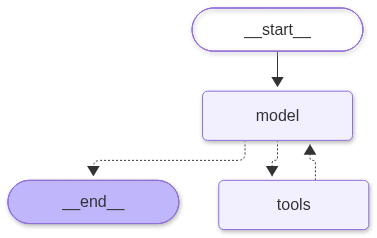

In [44]:
# Basic agent
from langchain.agents import create_agent

simple_agent = create_agent(
    model=model,
    tools=[web_search]
)
simple_agent

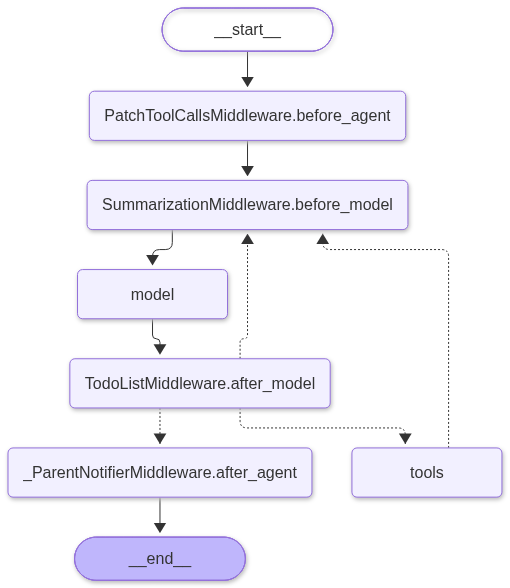

In [46]:
# Create a deep agent
#Prompt

#Agent
from deepagents import create_deep_agent
from langchain.agents.middleware import (TodoListMiddleware,SummarizationMiddleware)

deepagent = create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher",
    middleware = [
        TodoListMiddleware(),
        SummarizationMiddleware(
            model=model,
            trigger=("tokens", 3000),
            keep=("messages", 4),
            trim_tokens_to_summarize=2000
        )
    ]
)
deepagent

In [47]:
result = deepagent.invoke({"messages":[
    {
     "role": "user",
            "content": """
            What is deepagent?
            """
    }
    ]})
result

{'messages': [HumanMessage(content='\n            What is deepagent?\n            ', additional_kwargs={}, response_metadata={}, id='9a509680-735b-4750-8fc2-ad91460ed091'),
  AIMessage(content='**DeepAgent** is a term that can refer to a few related concepts, depending on the context in which it’s used. Below are the most common meanings:\n\n---\n\n### 1. Deep Reinforcement Learning Agent (often shortened to “deep agent”)\n- **Definition:** An autonomous software entity that learns to make decisions by interacting with an environment, using deep neural networks to approximate value functions or policies.\n- **Key Features:**\n  - **Deep Learning:** Utilizes multilayer neural networks (CNNs, RNNs, Transformers, etc.) to process high‑dimensional inputs (e.g., images, raw sensor data).\n  - **Reinforcement Learning (RL):** Learns through trial‑and‑error, receiving rewards or penalties for actions.\n  - **Applications:** Game playing (e.g., AlphaGo, Atari), robotics, autonomous driving, fi

In [48]:
result["messages"][-1].content

'**DeepAgent** is a term that can refer to a few related concepts, depending on the context in which it’s used. Below are the most common meanings:\n\n---\n\n### 1. Deep Reinforcement Learning Agent (often shortened to “deep agent”)\n- **Definition:** An autonomous software entity that learns to make decisions by interacting with an environment, using deep neural networks to approximate value functions or policies.\n- **Key Features:**\n  - **Deep Learning:** Utilizes multilayer neural networks (CNNs, RNNs, Transformers, etc.) to process high‑dimensional inputs (e.g., images, raw sensor data).\n  - **Reinforcement Learning (RL):** Learns through trial‑and‑error, receiving rewards or penalties for actions.\n  - **Applications:** Game playing (e.g., AlphaGo, Atari), robotics, autonomous driving, finance, recommendation systems, and more.\n- **Typical Algorithms:** Deep Q‑Network (DQN), Deep Deterministic Policy Gradient (DDPG), Proximal Policy Optimization (PPO), Soft Actor‑Critic (SAC),

In [49]:
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================


            What is deepagent?
            
================================== Ai Message ==================================

**DeepAgent** is a term that can refer to a few related concepts, depending on the context in which it’s used. Below are the most common meanings:

---

### 1. Deep Reinforcement Learning Agent (often shortened to “deep agent”)
- **Definition:** An autonomous software entity that learns to make decisions by interacting with an environment, using deep neural networks to approximate value functions or policies.
- **Key Features:**
  - **Deep Learning:** Utilizes multilayer neural networks (CNNs, RNNs, Transformers, etc.) to process high‑dimensional inputs (e.g., images, raw sensor data).
  - **Reinforcement Learning (RL):** Learns through trial‑and‑error, receiving rewards or penalties for actions.
  - **Applications:** Game playing (e.g., AlphaGo, Atari), robotics, autonomous drivi

In [50]:
for message in result["messages"]:
    if getattr(message, "tool_calls", None):
        for tool_call in message.tool_calls:
            print(tool_call["name"])
            print(tool_call["args"])

In [35]:
result["files"]

{}